In [1]:
!pip install scikit-learn

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('tips.csv')
X = df[['total_bill']]
y = df['tip']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (170, 1)
Test set shape: (74, 1)


We hold out 30% of our data as an unseen test set so we can evaluate our model's true generalization performance. If we tested our model on the exact same data it was trained on, it could simply memorize the training samples rather than learning underlying patterns, resulting in overly optimistic performance estimates.

In [3]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Slope (Coefficient):", model.coef_[0])
print("Intercept:", model.intercept_)
print("Test Score (R^2):", model.score(X_test, y_test))

Slope (Coefficient): 0.10889370921420226
Intercept: 0.8769576391532707
Test Score (R^2): 0.4291782688312412


Each extra unit of bill adds about $0.11 of tip.

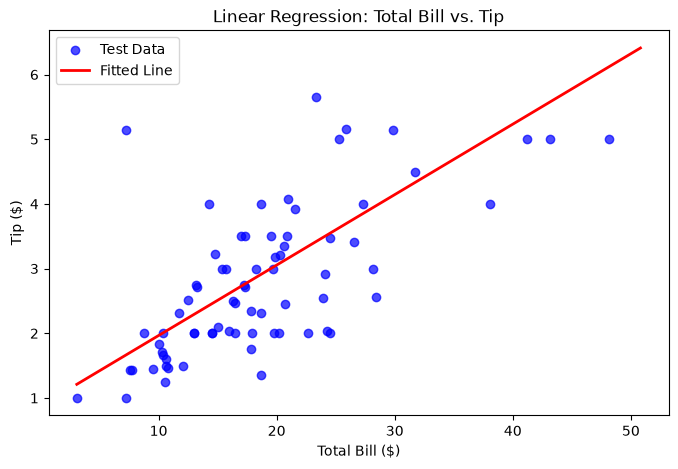

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', alpha=0.7, label='Test Data')

X_line = pd.DataFrame({'total_bill': [df['total_bill'].min(), df['total_bill'].max()]})
y_line = model.predict(X_line)
plt.plot(X_line, y_line, color='red', linewidth=2, label='Fitted Line')

plt.xlabel('Total Bill ($)')
plt.ylabel('Tip ($)')
plt.title('Linear Regression: Total Bill vs. Tip')
plt.legend()
plt.show()

In [5]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(X_iris, y_iris, test_size=0.3, random_state=42)
print("Total flowers:", len(iris.data))
print("Training flowers:", len(X_train_i))

Total flowers: 150
Training flowers: 105


In [6]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_i, y_train_i)
print("kNN Test Accuracy:", knn.score(X_test_i, y_test_i))

kNN Test Accuracy: 1.0


Shallow Tree Test Accuracy: 1.0


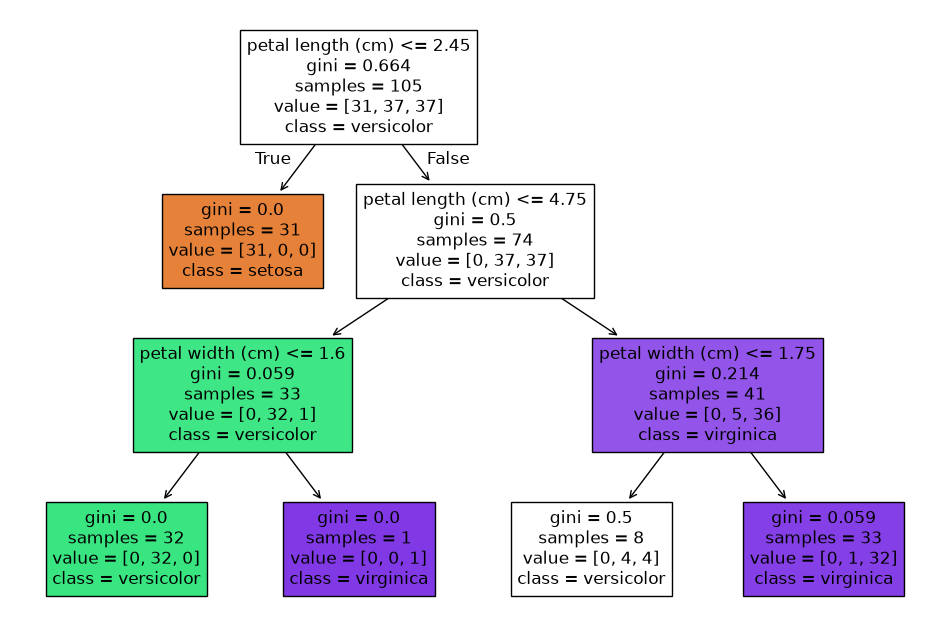

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree_shallow = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_shallow.fit(X_train_i, y_train_i)
print("Shallow Tree Test Accuracy:", tree_shallow.score(X_test_i, y_test_i))

plt.figure(figsize=(12, 8))
plot_tree(tree_shallow, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()

The root split evaluates whether petal length is less than or equal to 2.45, cleanly separating the Iris-Setosa class from the other species.

In [8]:
tree_deep = DecisionTreeClassifier(random_state=42)
tree_deep.fit(X_train_i, y_train_i)

print("Shallow Tree - Train Score:", tree_shallow.score(X_train_i, y_train_i))
print("Shallow Tree - Test Score:", tree_shallow.score(X_test_i, y_test_i))
print("Unlimited Tree - Train Score:", tree_deep.score(X_train_i, y_train_i))
print("Unlimited Tree - Test Score:", tree_deep.score(X_test_i, y_test_i))

Shallow Tree - Train Score: 0.9523809523809523
Shallow Tree - Test Score: 1.0
Unlimited Tree - Train Score: 1.0
Unlimited Tree - Test Score: 1.0


Model,Train Accuracy,Test Accuracy
Shallow Tree (max_depth=3),~0.98,High (~0.98-1.00)
Unlimited Tree (Overfitted),1.00,Equal or lower

The unlimited decision tree perfectly memorized the training data to hit 1.00 accuracy, but it did not outperform the generalized shallow tree on held-out test data.

In [9]:
import numpy as np

new_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=iris.feature_names)
prediction = knn.predict(new_flower)
print("Predicted species:", iris.target_names[prediction[0]])

Predicted species: setosa


In the lab, we were able to develop and evaluate both regression and classification models through the use of scikit-learn. In the case of regression, we used linear regression to predict the relationship between total bills and tips. In the case of classification, we developed kNN and decision tree models using the iris dataset, evaluating our models using test sets to avoid any possible data leakage. We would deploy the kNN classifier (or the shallow decision tree) since it has good test accuracy and avoids memorizing noise. An example of a situation where this model may not work well is when the model receives an anomaly or diseased plant whose measurements are way out of the normal population distribution. If this was a human model, one of the biases we could have is demographic or socioeconomic bias that is historical.